# Social Media Engagement Analytics Using Python

**Problem Statement**

Social media platforms generate massive volumes of engagement data—likes, comments, shares, impressions, watch time, and more. Analyzing such data helps companies understand user behavior, identify trends, and improve content performance.
In this assignment, you will work with a social media dataset containing social media engagement metrics. The task involves data cleaning, transformation, NumPy/Pandas operations, exploratory data analysis, visualizations, and generating insights.

Dataset Provided:

**social_media_engagement_5000.csv**


**Assignment Tasks**

**Task 1**—

Data Import & Setup

Import CSV using Pandas

Check/convert data types

Convert date columns to datetime

Use NumPy arrays for basic array operations


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from google.colab import files
upload= files.upload()

Saving social_media_engagement_5000.csv to social_media_engagement_5000.csv


In [3]:
df=pd.read_csv("social_media_engagement_5000.csv")
print(df)

      user_id   age  gender    country  post_id post_type post_category  \
0       25795  43.0  Female     Brazil   496713     image       fitness   
1       10860  33.0    Male     Brazil   157326      reel          food   
2       86820  32.0  Female         UK   109864      text          food   
3       64886  51.0   Other     France   848877      text       fitness   
4       16265  34.0   Other         UK   449706     image       fitness   
...       ...   ...     ...        ...      ...       ...           ...   
4995    59500  44.0    Male  Australia   441541     video     education   
4996    22100  38.0   Other        UAE   677076      reel     education   
4997    67021  63.0  Female        USA   273595      text        travel   
4998    29800  13.0  Female    Germany   785644     video       fitness   
4999    73400  54.0   Other      Japan   712252      text        travel   

        likes  comments  shares  watch_time_sec  impression_count   posted_at  \
0      7011.0     

In [4]:
df.head()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,17-12-2022,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,02-06-2023,5963,False,mobile,negative,#fitness,0.201493
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,07-05-2023,501783,False,tablet,positive,#foodie,0.137345
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,12-02-2023,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,23-05-2023,383936,False,mobile,negative,#travel,2.777372


imported the dataset by using pandas and displayed the first five rows of the dataset to understand the data

In [5]:
df.columns

Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate'],
      dtype='object')

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   user_id           5000 non-null   int64  
 1   age               4850 non-null   float64
 2   gender            4850 non-null   object 
 3   country           5000 non-null   object 
 4   post_id           5000 non-null   int64  
 5   post_type         5000 non-null   object 
 6   post_category     5000 non-null   object 
 7   likes             4850 non-null   float64
 8   comments          4850 non-null   float64
 9   shares            4850 non-null   float64
 10  watch_time_sec    5000 non-null   int64  
 11  impression_count  5000 non-null   int64  
 12  posted_at         5000 non-null   object 
 13  follower_count    5000 non-null   int64  
 14  is_verified       5000 non-null   bool   
 15  device_type       5000 non-null   object 
 16  sentiment         4850 non-null   object 


2)Check/convert data types

In [7]:
df.dtypes

,0
user_id,int64
age,float64
gender,object
country,object
post_id,int64
post_type,object
post_category,object
likes,float64
comments,float64
shares,float64


In [8]:
df["age"]=df["age"].astype("Int64")
df["likes"]=df["likes"].astype("Int64")
df["comments"]=df["comments"].astype("Int64")
df["shares"]=df["shares"].astype("Int64")



In [9]:
df.dtypes

,0
user_id,int64
age,Int64
gender,object
country,object
post_id,int64
post_type,object
post_category,object
likes,Int64
comments,Int64
shares,Int64


**Checked the data types using df.dtypes. Then I converted the age, likes, comments, and shares into integer format because they contain whole numbers and some missing values.**

3)Convert date columns to datetime


In [10]:
df["posted_at"]=pd.to_datetime(df["posted_at"],dayfirst=True)


**Then converted the posted_at column into datetime format**

In [11]:
df.dtypes

,0
user_id,int64
age,Int64
gender,object
country,object
post_id,int64
post_type,object
post_category,object
likes,Int64
comments,Int64
shares,Int64


In [12]:
df.head()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43,Female,Brazil,496713,image,fitness,7011,354,1157,5726,44650,2022-12-17,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33,Male,Brazil,157326,reel,food,11750,2606,1807,5947,80216,2023-06-02,5963,False,mobile,negative,#fitness,0.201493
2,86820,32,Female,UK,109864,text,food,4862,344,955,6946,44858,2023-05-07,501783,False,tablet,positive,#foodie,0.137345
3,64886,51,Other,France,848877,text,fitness,5350,1083,1049,229,70455,2023-02-12,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34,Other,UK,449706,image,fitness,12682,2735,1300,4798,6019,2023-05-23,383936,False,mobile,negative,#travel,2.777372


4)Use NumPy arrays for basic array operations


In [13]:
likes=np.array(df["likes"].dropna())
print("Total likes:",np.sum(likes))
print("Average likes:",np.mean(likes))
print("Maximum likes:",np.max(likes))
print("Minimum likes:",np.min(likes))

Total likes: 49019162
Average likes: 10107.043711340206
Maximum likes: 19998
Minimum likes: 10


 **converted the likes column into a NumPy array using np.array(),used dropna() to remove missing values before calculation.Then calculated the total, average, maximum, and minimum likes using NumPy functions.**

**Task 2 — Data Cleaning**

Cleaning Missing Data
Detect missing values (isnull(), isna())

Handle using: dropna(), fillna(), median/mode, forward/backward-fill


In [14]:
df.isnull().sum()

,0
user_id,0
age,150
gender,150
country,0
post_id,0
post_type,0
post_category,0
likes,150
comments,150
shares,150


**In this dataset has 150 missing values each in age, gender, likes, comments, shares, and sentiment.**

2)Handle using: dropna(), fillna(), median/mode, forward/backward-fill


In [15]:
df["age"]=df["age"].fillna(df["age"].median())
df["likes"]=df["likes"].fillna(round(df["likes"].median()))
df["comments"]=df["comments"].fillna(df["comments"].median())
df["shares"]=df["shares"].fillna(df["shares"].median())
df["sentiment"]=df["sentiment"].fillna("Unknown")
df["gender"]=df["gender"].fillna(df["gender"].mode()[0])




In [16]:
df.isnull().sum()

,0
user_id,0
age,0
gender,0
country,0
post_id,0
post_type,0
post_category,0
likes,0
comments,0
shares,0


**Checked the missing values in my dataset and filled them using suitable methods.For numerical columns like age,likes,comments and shares I used the median. For gender,I used the mode because it contains categorical values,then filled the missing sentiment values with "Unknown" to keep the records for analysis.**

**Duplicate Handling**

Identify & remove duplicates


In [17]:
df.duplicated().sum()

np.int64(0)

**The duplicated().sum() function is used to find duplicate rows in the dataset. The result is 0, which means there are no duplicate rows. Therefore, no records need to be removed**

**Data Formatting**

Fix incorrect data types

Standardize categories (e.g., gender labels)

Correct unrealistic values in likes, comments, shares


In [18]:
df["age"]=df["age"].astype("Int64")
df["likes"]=df["likes"].astype("Int64")
df["comments"]=df["comments"].astype("Int64")
df["shares"]=df["shares"].astype("Int64")
df["posted_at"]=pd.to_datetime(df["posted_at"],dayfirst=True)

df.isnull().sum()

,0
user_id,0
age,0
gender,0
country,0
post_id,0
post_type,0
post_category,0
likes,0
comments,0
shares,0


**Checked the data types using df.dtypes. Then I converted the age, likes, comments, and shares into integer format because they contain whole numbers and some missing values.Then converted the posted_at column into datetime format**

2)Standardize categories (e.g., gender labels)

In [19]:
df["gender"].unique()
df["country"].unique()
df["post_type"].unique()
df["post_category"].unique()
df["is_verified"].unique()
df["device_type"].unique()
df["sentiment"].unique()

print(df["gender"].unique())
print(df["country"].unique())
print(df["post_type"].unique())
print(df["post_category"].unique())
print(df["is_verified"].unique())
print(df["device_type"].unique())
print(df["sentiment"].unique())

['Female' 'Male' 'Other']
['Brazil' 'UK' 'France' 'Canada' 'Japan' 'Australia' 'India' 'UAE'
 'Germany' 'USA']
['image' 'reel' 'text' 'video']
['fitness' 'food' 'tech' 'travel' 'fashion' 'lifestyle' 'education'
 'music']
[False  True]
['mobile' 'tablet' 'desktop']
['negative' 'positive' 'neutral' 'Unknown']


In [20]:
df["gender"]=df["gender"].str.strip().str.title()
df["country"]=df["country"].str.strip().str.title()
df["post_type"]=df["post_type"].str.strip().str.title()
df["post_category"]=df["post_category"].str.strip().str.title()
df["device_type"]=df["device_type"].str.strip().str.title()
df["sentiment"]=df["sentiment"].str.strip().str.title()

df.head()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43,Female,Brazil,496713,Image,Fitness,7011,354,1157,5726,44650,2022-12-17,81734,False,Mobile,Negative,#foodie #travel #love,0.190862
1,10860,33,Male,Brazil,157326,Reel,Food,11750,2606,1807,5947,80216,2023-06-02,5963,False,Mobile,Negative,#fitness,0.201493
2,86820,32,Female,Uk,109864,Text,Food,4862,344,955,6946,44858,2023-05-07,501783,False,Tablet,Positive,#foodie,0.137345
3,64886,51,Other,France,848877,Text,Fitness,5350,1083,1049,229,70455,2023-02-12,480212,False,Mobile,Negative,#music #foodie #fun,0.106195
4,16265,34,Other,Uk,449706,Image,Fitness,12682,2735,1300,4798,6019,2023-05-23,383936,False,Mobile,Negative,#travel,2.777372


In [21]:
df["gender"].unique()
df["country"].unique()
df["post_type"].unique()
df["post_category"].unique()
df["is_verified"].unique()
df["device_type"].unique()
df["sentiment"].unique()

print(df["gender"].unique())
print(df["country"].unique())
print(df["post_type"].unique())
print(df["post_category"].unique())
print(df["is_verified"].unique())
print(df["device_type"].unique())
print(df["sentiment"].unique())

['Female' 'Male' 'Other']
['Brazil' 'Uk' 'France' 'Canada' 'Japan' 'Australia' 'India' 'Uae'
 'Germany' 'Usa']
['Image' 'Reel' 'Text' 'Video']
['Fitness' 'Food' 'Tech' 'Travel' 'Fashion' 'Lifestyle' 'Education'
 'Music']
[False  True]
['Mobile' 'Tablet' 'Desktop']
['Negative' 'Positive' 'Neutral' 'Unknown']


**The categorical columns are standardized to maintain a consistent format in the dataset. The str.strip() function removes unwanted spaces from the beginning and end of the text, while str.title() converts the first letter of each word into uppercase. This helps avoid differences in category names caused by inconsistent formatting. Finally, df.head() displays the first five rows to check the updated data.**

3)Correct unrealistic values in likes, comments, shares

In [22]:
print((df["likes"]<0).sum())
print((df["comments"]<0).sum())
print((df["shares"]<0).sum())

0
0
0


**Negative values in likes, comments, and shares are considered invalid because engagement counts cannot be negative. The dataset contains no negative values in these columns.Since no negative values are present, no changes are required.**

**Feature Cleaning**

Extract hashtag count

Clean sentiment labels


In [23]:
df["hashtag_count"]=df["hashtags"].str.count("#")
df[["hashtags","hashtag_count"]].head()

,hashtags,hashtag_count
0,#foodie #travel #love,3
1,#fitness,1
2,#foodie,1
3,#music #foodie #fun,3
4,#travel,1


**The str.count() function is used to count the number of hashtags in each post. The # symbol is counted from the hashtags column. A new column called hashtag_count is created to store the total number of hashtags in each post. This helps analyze the use of hashtags in social media posts.**

2)Clean sentiment labels

In [24]:
df["sentiment"]=df["sentiment"].str.strip().str.title()
df["sentiment"].unique()

array(['Negative', 'Positive', 'Neutral', 'Unknown'], dtype=object)

**The sentiment column is cleaned to maintain consistent labels in the dataset. The str.strip() function removes unwanted spaces, and str.title() converts the first letter into uppercase. The unique() function displays the different sentiment categories after cleaning.**

# Task 3 — Data Exploration using Pandas

**Perform the following:**

1. View dataset structure using head(), tail(), shape, and columns.

2. Check data types and info with info() and dtypes.

3. Generate summary statistics using describe().

4. Analyze categorical distributions using value_counts(), unique(), and nunique().

5. Create a correlation matrix for numeric fields.

6. Use groupby() to summarize metrics (e.g., avg likes by post type, impressions by country).





In [25]:
df.head()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
0,25795,43,Female,Brazil,496713,Image,Fitness,7011,354,1157,5726,44650,2022-12-17,81734,False,Mobile,Negative,#foodie #travel #love,0.190862,3
1,10860,33,Male,Brazil,157326,Reel,Food,11750,2606,1807,5947,80216,2023-06-02,5963,False,Mobile,Negative,#fitness,0.201493,1
2,86820,32,Female,Uk,109864,Text,Food,4862,344,955,6946,44858,2023-05-07,501783,False,Tablet,Positive,#foodie,0.137345,1
3,64886,51,Other,France,848877,Text,Fitness,5350,1083,1049,229,70455,2023-02-12,480212,False,Mobile,Negative,#music #foodie #fun,0.106195,3
4,16265,34,Other,Uk,449706,Image,Fitness,12682,2735,1300,4798,6019,2023-05-23,383936,False,Mobile,Negative,#travel,2.777372,1


In [26]:
df.tail()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
4995,59500,44,Male,Australia,441541,Video,Education,16210,2013,1837,6190,42977,2022-06-25,646147,False,Mobile,Positive,#travel #fun,0.466761,2
4996,22100,38,Other,Uae,677076,Reel,Education,16924,2734,1583,7764,34196,2022-11-18,584603,False,Desktop,Negative,#foodie #reels,0.621155,2
4997,67021,63,Female,Usa,273595,Text,Travel,13487,1497,167,7466,23680,2023-04-06,483550,False,Desktop,Positive,#lifestyle #tech,0.679688,2
4998,29800,13,Female,Germany,785644,Video,Fitness,16894,1289,1713,4991,89013,2022-05-16,183295,False,Tablet,Positive,#reels #love #fitness,0.223518,3
4999,73400,54,Other,Japan,712252,Text,Travel,14830,503,1798,3743,14234,2023-03-04,585760,False,Desktop,Neutral,#foodie #lifestyle #fashion,1.203527,3


In [27]:
df.shape

(5000, 20)

In [119]:
df.columns

Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate',
       'hashtag_count'],
      dtype='object')

**The head() function displays the first five rows, while tail() displays the last five rows of the dataset.The shape function shows the total number of rows and columns.The columns function displays all the column names.These functions help understand the basic structure of the dataset.**

2)Check data types and info with info() and dtypes.

In [28]:
df.dtypes

,0
user_id,int64
age,Int64
gender,object
country,object
post_id,int64
post_type,object
post_category,object
likes,Int64
comments,Int64
shares,Int64


In [29]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   user_id           5000 non-null   int64         
 1   age               5000 non-null   Int64         
 2   gender            5000 non-null   object        
 3   country           5000 non-null   object        
 4   post_id           5000 non-null   int64         
 5   post_type         5000 non-null   object        
 6   post_category     5000 non-null   object        
 7   likes             5000 non-null   Int64         
 8   comments          5000 non-null   Int64         
 9   shares            5000 non-null   Int64         
 10  watch_time_sec    5000 non-null   int64         
 11  impression_count  5000 non-null   int64         
 12  posted_at         5000 non-null   datetime64[ns]
 13  follower_count    5000 non-null   int64         
 14  is_verified       5000 n

**The info() function provides an overview of the dataset, including column names, data types, and non-null values. The dtypes function displays the data type of each column separately**

3)Generate summary statistics using describe().


In [30]:
df.describe(include="number")

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,follower_count,engagement_rate,hashtag_count
count,5000.000000,5000.0,5000.000000,5000.0,5000.0,5000.0,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,54561.890800,38.4404,548042.909000,10107.0124,1502.0398,1002.9106,4014.503200,50013.732800,393698.224800,0.964356,1.998600
std,26090.370121,14.687151,260646.957267,5702.293014,856.393312,570.8552,2308.096459,28844.939104,230927.884535,5.318029,0.812853
min,10055.000000,13.0,100068.000000,10.0,0.0,0.0,0.000000,105.000000,87.000000,0.006363,1.000000
25%,32309.500000,26.0,322543.500000,5235.0,792.0,511.0,2017.750000,24988.250000,194480.000000,0.145781,1.000000
50%,54374.500000,38.0,548077.500000,10106.0,1497.0,1012.0,4034.500000,49934.500000,388982.000000,0.253896,2.000000
75%,77180.500000,51.0,771574.500000,14959.0,2235.25,1483.0,6020.250000,74662.250000,589744.250000,0.504794,3.000000
max,99963.000000,64.0,999455.000000,19998.0,2999.0,1999.0,7998.000000,99995.000000,799533.000000,191.504348,3.000000


**The describe() function provides statistical information about the numerical columns in the dataset.It displays values such as count, mean, standard deviation, minimum, and maximum.It also shows the 25%,50% and 75% percentiles.**

4)Analyze categorical distributions using value_counts(), unique(), and nunique().


In [31]:
df["post_type"].value_counts()

,count
post_type,
Reel,1283
Image,1247
Text,1245
Video,1225


In [32]:
df["sentiment"].unique()

array(['Negative', 'Positive', 'Neutral', 'Unknown'], dtype=object)

In [33]:
df["country"].nunique()

10

**The value_counts() function shows how many times each post type appears in the dataset.The unique() function displays the different sentiment categories without repeating them.The nunique() function counts the number of unique countries.**

5)Create a correlation matrix for numeric fields.


In [34]:
df.corr(numeric_only=True)

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,follower_count,is_verified,engagement_rate,hashtag_count
user_id,1.000000,-0.006688,0.020051,0.025811,-0.033395,0.013763,-0.016847,0.015326,0.010124,0.004058,-0.004282,-0.013692
age,-0.006688,1.000000,-0.013153,-0.036322,-0.007284,0.013871,0.005542,0.013322,-0.024894,-0.000079,0.008039,0.007173
post_id,0.020051,-0.013153,1.000000,0.014527,-0.010540,0.001846,0.018374,-0.007709,-0.002844,0.025208,0.010139,0.007344
likes,0.025811,-0.036322,0.014527,1.000000,-0.018421,0.004712,0.008711,0.007952,-0.022982,-0.016200,0.093520,-0.002189
comments,-0.033395,-0.007284,-0.010540,-0.018421,1.000000,0.006142,-0.016351,-0.009395,-0.011733,-0.012398,0.000051,-0.015230
shares,0.013763,0.013871,0.001846,0.004712,0.006142,1.000000,0.014658,-0.005204,-0.010783,0.007025,0.021724,0.013379
watch_time_sec,-0.016847,0.005542,0.018374,0.008711,-0.016351,0.014658,1.000000,-0.004335,0.002761,0.012326,-0.001148,-0.023301
impression_count,0.015326,0.013322,-0.007709,0.007952,-0.009395,-0.005204,-0.004335,1.000000,-0.015513,0.008317,-0.232226,-0.002714
follower_count,0.010124,-0.024894,-0.002844,-0.022982,-0.011733,-0.010783,0.002761,-0.015513,1.000000,-0.017808,0.002292,0.008802
is_verified,0.004058,-0.000079,0.025208,-0.016200,-0.012398,0.007025,0.012326,0.008317,-0.017808,1.000000,0.005528,0.001396


**The corr() function is used to find the relationship between numerical columns in the dataset.The numeric_only=True option selects only numerical columns for calculation. Correlation values range from -1 to +1.Positive values show that two variables tend to increase together,while negative values show that one tends to decrease as the other increases.Values near zero indicate a weak linear relationship.**

6)Use groupby() to summarize metrics (e.g., avg likes by post type, impressions by country).


In [35]:
df.groupby("post_type")["likes"].mean()

,likes
post_type,
Image,10104.878107
Reel,10037.819953
Text,10100.163855
Video,10188.613878


**The groupby() function is used to group the data based on post type.The mean() function calculates the average likes for each post type.This helps compare the performance of different types of social media posts.**

In [36]:
df.groupby("country")["impression_count"].sum()

,impression_count
country,
Australia,23834767
Brazil,24793360
Canada,24984716
France,25656926
Germany,23816649
India,28067377
Japan,23418816
Uae,24610992
Uk,25201861


**The groupby() function groups the data based on country.The sum() function calculates the total impressions for each country using the impression_count column.This helps compare the total impressions generated across different countries.**

**Task 4 — Data Wrangling**

Use merge, concat, or join if combining DataFrames.

Create new fields such as engagement_score, log-transformed metrics (optional), and hashtag_count.

Perform groupby summaries by post_type, country, and sentiment.


In [37]:
df1=df.head(5)
df2=df.tail(5)
new_df=pd.concat([df1, df2])
new_df

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
0,25795,43,Female,Brazil,496713,Image,Fitness,7011,354,1157,5726,44650,2022-12-17,81734,False,Mobile,Negative,#foodie #travel #love,0.190862,3
1,10860,33,Male,Brazil,157326,Reel,Food,11750,2606,1807,5947,80216,2023-06-02,5963,False,Mobile,Negative,#fitness,0.201493,1
2,86820,32,Female,Uk,109864,Text,Food,4862,344,955,6946,44858,2023-05-07,501783,False,Tablet,Positive,#foodie,0.137345,1
3,64886,51,Other,France,848877,Text,Fitness,5350,1083,1049,229,70455,2023-02-12,480212,False,Mobile,Negative,#music #foodie #fun,0.106195,3
4,16265,34,Other,Uk,449706,Image,Fitness,12682,2735,1300,4798,6019,2023-05-23,383936,False,Mobile,Negative,#travel,2.777372,1
4995,59500,44,Male,Australia,441541,Video,Education,16210,2013,1837,6190,42977,2022-06-25,646147,False,Mobile,Positive,#travel #fun,0.466761,2
4996,22100,38,Other,Uae,677076,Reel,Education,16924,2734,1583,7764,34196,2022-11-18,584603,False,Desktop,Negative,#foodie #reels,0.621155,2
4997,67021,63,Female,Usa,273595,Text,Travel,13487,1497,167,7466,23680,2023-04-06,483550,False,Desktop,Positive,#lifestyle #tech,0.679688,2
4998,29800,13,Female,Germany,785644,Video,Fitness,16894,1289,1713,4991,89013,2022-05-16,183295,False,Tablet,Positive,#reels #love #fitness,0.223518,3
4999,73400,54,Other,Japan,712252,Text,Travel,14830,503,1798,3743,14234,2023-03-04,585760,False,Desktop,Neutral,#foodie #lifestyle #fashion,1.203527,3


**The first five rows and last five rows are selected from the original dataset. Both DataFrames are combined into a new DataFrame called new_df.This demonstrates how multiple DataFrames can be combined using Pandas.The concat() function is used to combine two DataFrames.**

2)Create new fields such as engagement_score, log-transformed metrics (optional), and hashtag_count.


In [38]:
df["engagement_score"]=df["likes"]+df["comments"]+df["shares"]
df[["likes","comments","shares","engagement_score"]].head()

,likes,comments,shares,engagement_score
0,7011,354,1157,8522
1,11750,2606,1807,16163
2,4862,344,955,6161
3,5350,1083,1049,7482
4,12682,2735,1300,16717


**A new column called engagement_score is created by adding likes, comments, and shares.This gives the total number of engagement interactions for each post.**

In [39]:
df[["hashtags","hashtag_count"]].head()

,hashtags,hashtag_count
0,#foodie #travel #love,3
1,#fitness,1
2,#foodie,1
3,#music #foodie #fun,3
4,#travel,1


**The hashtag_count column shows the number of hashtags used in each post.The values are calculated by counting the # symbol in the hashtags column.**

3)Perform groupby summaries by post_type, country, and sentiment.


In [40]:
df.groupby("post_type")["likes"].mean()

,likes
post_type,
Image,10104.878107
Reel,10037.819953
Text,10100.163855
Video,10188.613878


**The groupby() function groups the dataset based on post type.The mean() function calculates the average likes for each post type.**

In [41]:
df.groupby("country")["impression_count"].sum()

,impression_count
country,
Australia,23834767
Brazil,24793360
Canada,24984716
France,25656926
Germany,23816649
India,28067377
Japan,23418816
Uae,24610992
Uk,25201861


**The dataset is grouped based on country using the groupby() function.The sum() function calculates the total impressions for each country.**

In [42]:
df.groupby("sentiment")["engagement_rate"].mean()

,engagement_rate
sentiment,
Negative,1.038486
Neutral,0.991170
Positive,0.954800
Unknown,0.367493


**The groupby() function groups the posts based on their sentiment labels.The mean() function calculates the average engagement rate for each sentiment category.**

**Task 5 — Statistical Analysis**

Compute descriptive stats for likes, comments, shares, watch_time, engagement_rate, followers:

Mean, median, mode

Standard deviation, variance

Percentiles

(Optional) Skewness and kurtosis


In [43]:
data=df[["likes","comments","shares","watch_time_sec","engagement_rate","follower_count"]]
print("Mean:")
print(data.mean())

Mean:
likes               10107.0124
comments             1502.0398
shares               1002.9106
watch_time_sec       4014.5032
engagement_rate       0.964356
follower_count     393698.2248
dtype: Float64


In [44]:
print("Median:")
print(data.median())

Median:
likes               10106.0
comments             1497.0
shares               1012.0
watch_time_sec       4034.5
engagement_rate    0.253896
follower_count     388982.0
dtype: Float64


In [45]:
print("Mode:")
print(data.mode().iloc[0])

Mode:
likes               10106.0
comments             1497.0
shares               1012.0
watch_time_sec        916.0
engagement_rate    0.006363
follower_count     497502.0
Name: 0, dtype: Float64


**The mean,median and mode are used to understand the central values of numerical data.The mean()calculates the average,median() gives the middle value.The mode()finds the most frequently occurring value.**

2)Standard deviation, variance

In [46]:
print("Standard Deviation:")
print(data.std())
print("Variance:")
print(data.var())

Standard Deviation:
likes                5702.293014
comments              856.393312
shares                  570.8552
watch_time_sec       2308.096459
engagement_rate         5.318029
follower_count     230927.884535
dtype: Float64
Variance:
likes                 32516145.616169
comments                733409.504917
shares                   325875.65934
watch_time_sec         5327309.264243
engagement_rate             28.281435
follower_count     53327687855.630234
dtype: Float64


**Standard deviation and variance are used to understand how much the values differ from their average.The std()calculates the standard deviation,var() calculates the variance.**

3)Percentiles


In [47]:
print("25th Percentile:")
print(data.quantile(0.25))



25th Percentile:
likes                5235.0
comments              792.0
shares                511.0
watch_time_sec      2017.75
engagement_rate    0.145781
follower_count     194480.0
Name: 0.25, dtype: Float64


In [48]:
print("50th Percentile:")
print(data.quantile(0.50))

50th Percentile:
likes               10106.0
comments             1497.0
shares               1012.0
watch_time_sec       4034.5
engagement_rate    0.253896
follower_count     388982.0
Name: 0.5, dtype: Float64


In [49]:
print("75th Percentile:")
print(data.quantile(0.75))

75th Percentile:
likes                14959.0
comments             2235.25
shares                1483.0
watch_time_sec       6020.25
engagement_rate     0.504794
follower_count     589744.25
Name: 0.75, dtype: Float64


**Percentiles help understand how values are distributed in the dataset. The 25th percentile represents the lower 25% of values, the 50th percentile shows the middle value, and the 75th percentile represents the point below which 75% of values fall.**

**Task 6 — Data Visualization (Min. 8 Plots Required)**

**Matplotlib**

Scatter: likes vs impressions

Line: daily engagement trend

Bar: posts by category

Pie: gender distribution

Histogram: age

Box: engagement rate


**Scatter: likes vs impressions**

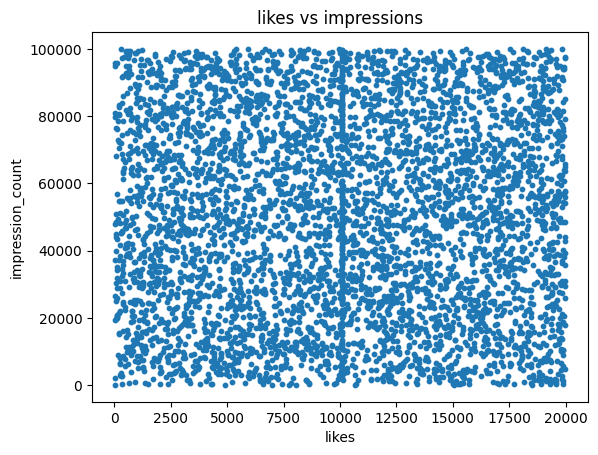

In [144]:
plt.scatter(df["likes"],df["impression_count"],s=10)
plt.xlabel("likes")
plt.ylabel("impression_count")
plt.title("likes vs impressions")
plt.show()

**The scatter plot shows the relationship between likes and impressions.The X-axis represents likes,and the Y-axis represents impressions. Each dot represents a social media post.The dots are spread across the chart without a clear pattern.**

**Line: daily engagement trend**

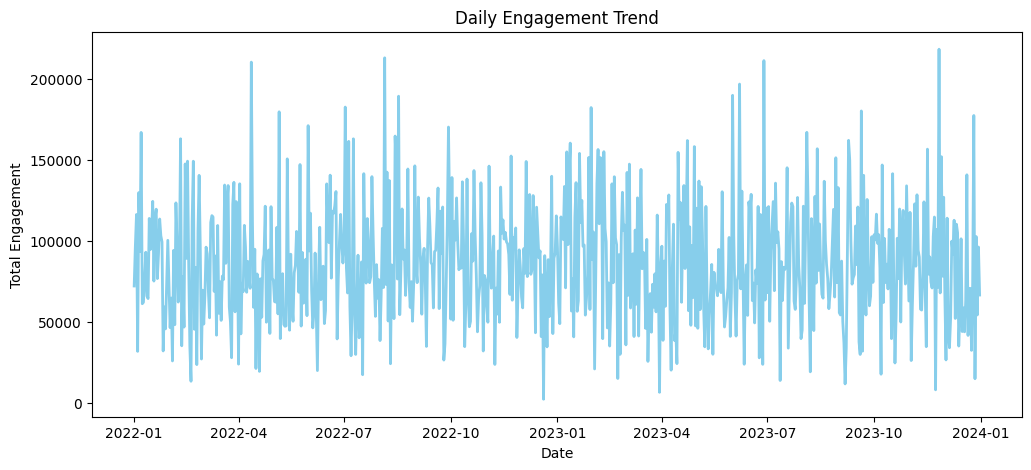

In [145]:
df["engagement_score"]=df["likes"]+df["comments"]+df["shares"]
daily=df.groupby("posted_at")["engagement_score"].sum()
plt.figure(figsize=(12, 5))
plt.plot(daily.index, daily.values, color="skyblue", linewidth=2)
plt.title("Daily Engagement Trend")
plt.xlabel("Date")
plt.ylabel("Total Engagement")
plt.show()

**The line chart shows the daily engagement trend of social media posts.The engagement score is calculated by adding likes, comments, and shares.The groupby()calculates the total engagement for each date.The sky-blue line shows how engagement increases and decreases over time.**

**Bar: posts by category**

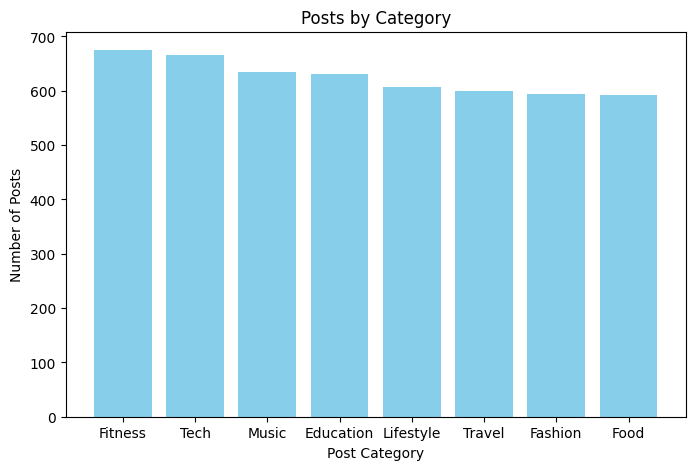

In [146]:
posts=df["post_category"].value_counts()
plt.figure(figsize=(8,5))
plt.bar(posts.index, posts.values,color="skyblue")
plt.title("Posts by Category")
plt.xlabel("Post Category")
plt.ylabel("Number of Posts")
plt.show()

**The bar chart shows the number of posts in each category.The value_counts() counts how many posts belong to each category.The X-axis represents the post categories, while the Y-axis shows the number of posts.**

**Pie: gender distribution**


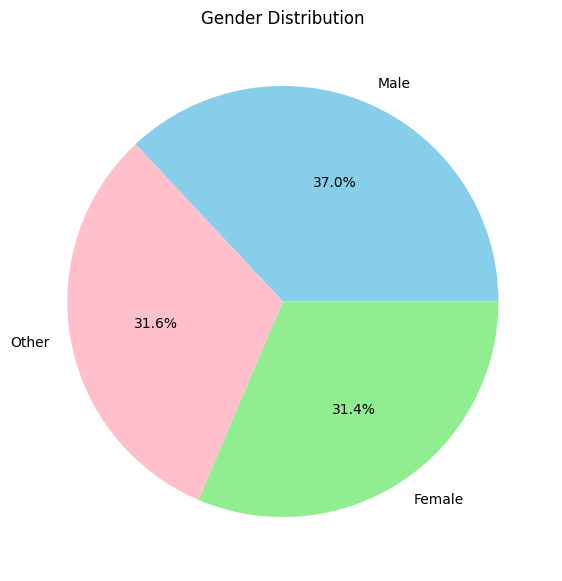

In [147]:
gender=df["gender"].value_counts()
colors=["skyblue","pink","lightgreen"]
plt.figure(figsize=(7,7))
plt.pie(gender.values, labels=gender.index, autopct="%1.1f%%",colors=colors)
plt.title("Gender Distribution")
plt.show()

**The pie chart shows the gender distribution in the dataset.The value_counts() counts the number of records in each gender category.Each slice represents a gender category,and the percentage is displayed on the chart.**

**Histogram: age**


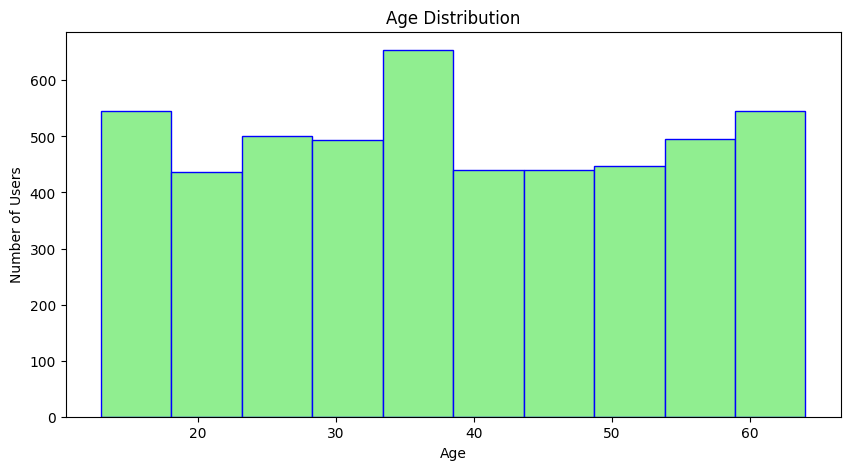

In [148]:
plt.figure(figsize=(10, 5))
plt.hist(df["age"],bins=10,color="lightgreen",edgecolor="blue")
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Users")
plt.show()

**The histogram shows the age distribution of users in the dataset. The bins=10 divides the ages into 10 groups. The X-axis represents age, while the Y-axis shows the number of users in each age group.**

**Box: engagement rate**

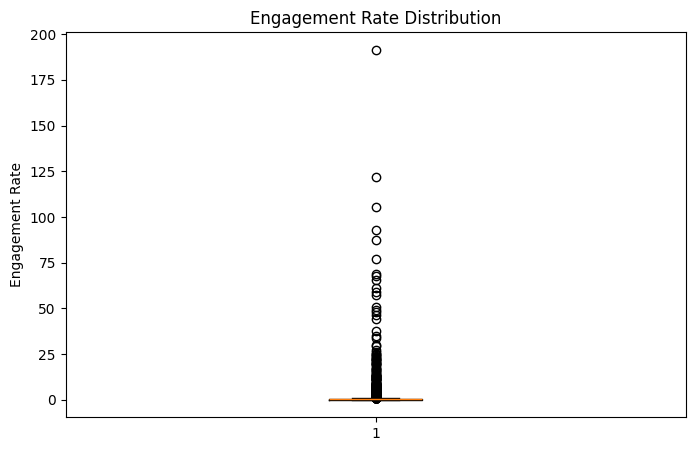

In [50]:
plt.figure(figsize=(8,5))
plt.boxplot(df["engagement_rate"].dropna())
plt.title("Engagement Rate Distribution")
plt.ylabel("Engagement Rate")
plt.show()

**The box plot shows the distribution of engagement rates in the dataset.It displays the median,spread of values,and possible outliers.**

# Seaborn

**Count plot: post type**


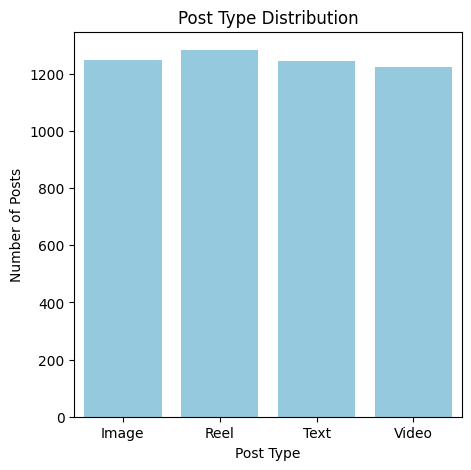

In [51]:
plt.figure(figsize=(5,5))
sns.countplot(x="post_type",data=df,color="skyblue")
plt.title("Post Type Distribution")
plt.xlabel("Post Type")
plt.ylabel("Number of Posts")
plt.show()

**The count plot shows the number of posts for each post type in the dataset.The X-axis represents different post types,the Y-axis shows the number of posts.The countplot() automatically counts the posts in each category.**

**Bar plot: avg likes by category**

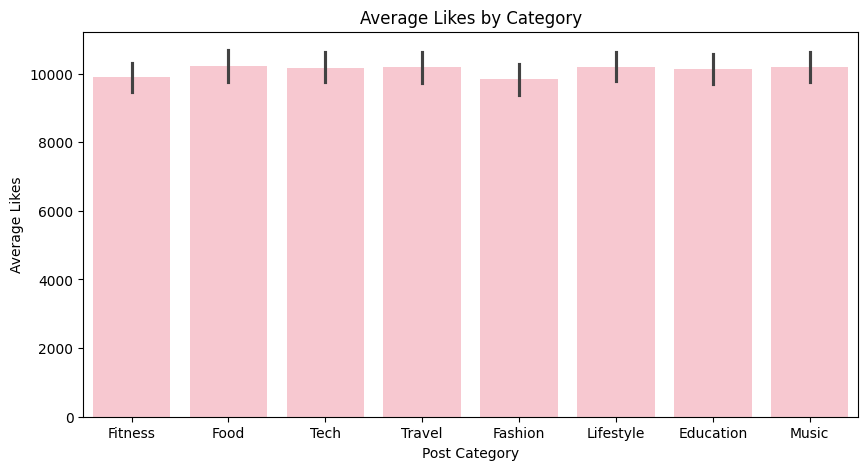

In [52]:
plt.figure(figsize=(10,5))
sns.barplot(x="post_category",y="likes",data=df,color="pink")
plt.title("Average Likes by Category")
plt.xlabel("Post Category")
plt.ylabel("Average Likes")
plt.show()

**The bar plot shows the average likes received by each post category.The sns.barplot()automatically calculates the average likes for each category.The X-axis represents the post categories,the Y-axis shows the average likes**

**Violin: followers vs sentiment**


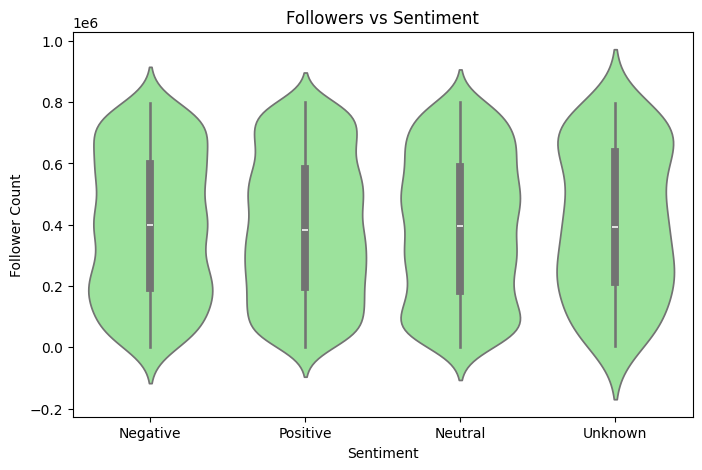

In [53]:
plt.figure(figsize=(8,5))
sns.violinplot(x="sentiment",y="follower_count",data=df,color="lightgreen")
plt.title("Followers vs Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Follower Count")
plt.show()

**The violin plot shows the distribution of followers across different sentiment categories.The X-axis represents sentiment,the Y-axis shows the follower count. The wider parts of the violin indicate where more values are concentrated.**

**Pair plot: numeric features**


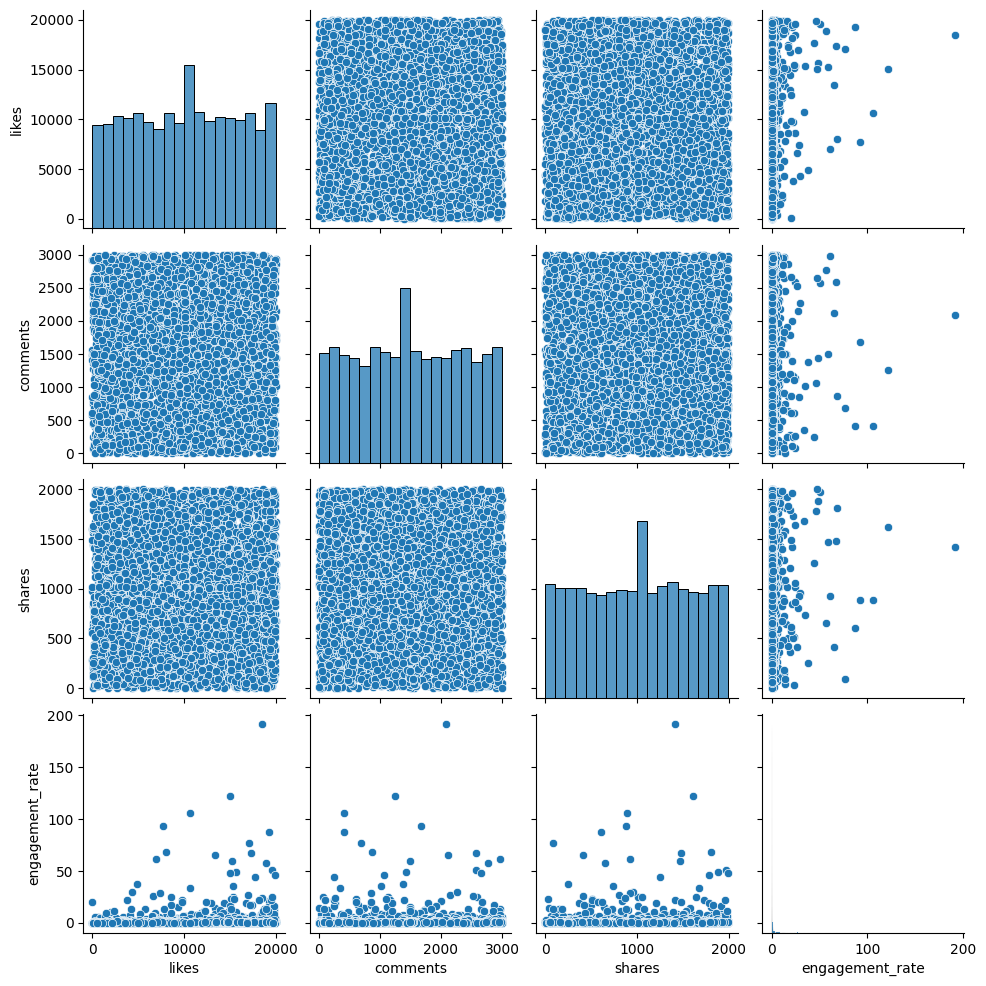

In [54]:
sns.pairplot(df[["likes","comments","shares","engagement_rate"]])
plt.show()

The pair plot shows the relationships between different numerical columns in the dataset.It compares likes,comments,shares and engagement rate.The scatter plots show how two variables are related,the diagonal plots show the distribution of each variable.

**Heatmap: correlation matrix**


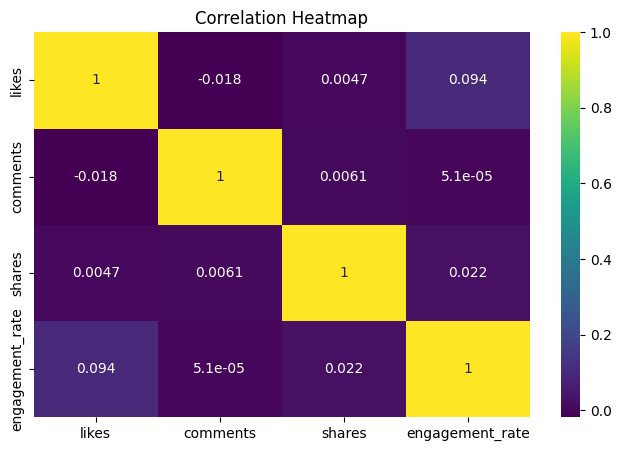

In [55]:
plt.figure(figsize=(8,5))
data=df[["likes","comments","shares","engagement_rate"]]
sns.heatmap(data.corr(),annot=True,cmap="viridis")
plt.title("Correlation Heatmap")
plt.show()

**The heatmap shows the correlation between numerical columns such as likes, comments,shares and engagement rate.The corr()calculates the correlation values and sns.heatmap() displays them using different colors.**

**Swarm plot: engagement vs device**


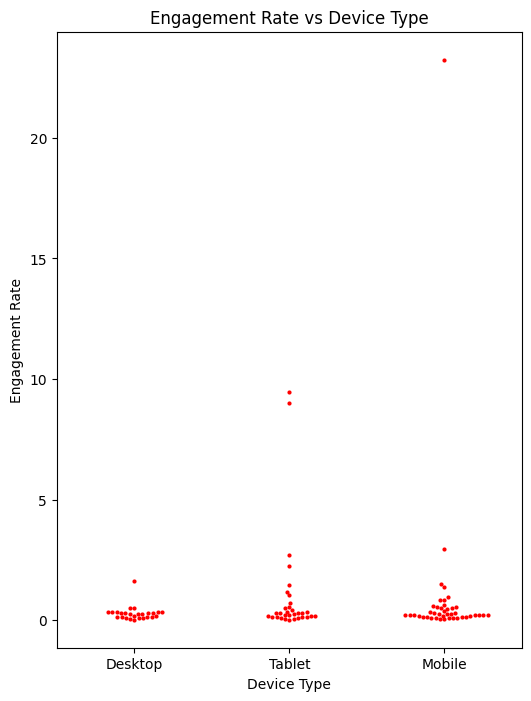

In [58]:
plt.figure(figsize=(6,8))
sns.swarmplot(x="device_type",y="engagement_rate",data=df.sample(100),color="red",size=3)
plt.title("Engagement Rate vs Device Type")
plt.xlabel("Device Type")
plt.ylabel("Engagement Rate")
plt.show()

**The swarm plot shows the engagement rate across different device types.The X-axis represents device types,the Y-axis shows engagement rates.Each dot represents one post and the dots are arranged to avoid overlapping.**

**Plotly (Interactive)**

Interactive line chart/bar chart/bubble/scatter chart


**Interactive Line Chart**

In [59]:
!pip install plotly
import plotly.express as px

In [60]:
daily=df.groupby("posted_at")["engagement_rate"].sum().reset_index()
fig = px.line(daily,x="posted_at",y="engagement_rate",title="Daily Engagement Trend")
fig.show()

**The line chart shows the daily engagement trend over time. It displays the total engagement for each date.**

**Interactive Bar Chart**

In [61]:
fig=px.bar(df,x="post_category",y="likes",title="Average Likes by Category",color="post_category",barmode="group")
fig.show()

**The bar chart compares likes across different post categories.Plotly automatically displays the average likes for each category.Different colors help identify each category.**

**Interactive Scatter Chart**

In [62]:
fig=px.scatter(df,x="likes",y="impression_count",title="Likes vs Impressions")
fig.show()

**The scatter chart shows the relationship between likes and impressions.Each dot represents a post.**

**Interactive Bubble Chart**

In [63]:
fig=px.scatter(df,x="likes",y="comments",size="shares",color="post_type",title="Likes vs Comments")
fig.show()

**The bubble chart compares likes and comments for different posts.The size of each bubble represents the number of shares,the colors represent post types.**

# Final Insights should Include following analysis

**Content Performance**

Which post types have highest engagement?

Best-performing content category?

Which countries have highest avg engagement rate?

**User Trends**

How age affects engagement

Performance difference for verified accounts



Which post types have highest engagement?

In [64]:
post_type=df.groupby("post_type")["engagement_rate"].mean().sort_values(ascending=False)
print(post_type)
print("Highest Engagement:",post_type.idxmax())

post_type
Video    1.122365
Text     1.064549
Image    0.895646
Reel     0.783047
Name: engagement_rate, dtype: float64
Highest Engagement: Video


**The analysis shows that Video posts have the highest average engagement rate of 1.12,followed by Text posts with 1.06 and Image posts with 0.90. Reel posts have the lowest average engagement rate of 0.78.This indicates that video content attracts more audience engagement compared to other post types.**

**Best-performing content category?**


In [65]:
category=df.groupby("post_category")["engagement_rate"].mean().sort_values(ascending=False)
print(category)
print("Best Category:",category.idxmax())

post_category
Food         1.358628
Tech         1.160475
Lifestyle    1.091019
Music        0.888803
Fitness      0.865628
Education    0.844222
Fashion      0.807109
Travel       0.702223
Name: engagement_rate, dtype: float64
Best Category: Food


**The analysis shows that Food content has the highest average engagement rate of 1.36,followed by Tech (1.16) and Lifestyle (1.09).Music,Fitness,Education,Fashion and Travel have comparatively lower engagement rates.This indicates that Food-related posts attract more audience engagement than other content categories.**

**Which countries have highest avg engagement rate?**

In [66]:
country=df.groupby("country")["engagement_rate"].mean().sort_values(ascending=False)
print(country)
print("Top Country:",country.idxmax())

country
Brazil       1.540704
Australia    1.324339
France       1.146402
Uae          1.112352
Canada       0.916659
Uk           0.850966
Japan        0.769623
Germany      0.759000
India        0.655005
Usa          0.576580
Name: engagement_rate, dtype: float64
Top Country: Brazil


**The analysis shows that Brazil has the highest average engagement rate of 1.54, followed by Australia (1.32),France(1.15),and UAE (1.11).Canada,UK,Japan, Germany,India and USA have comparatively lower average engagement rates.This indicates that posts from Brazil receive higher audience engagement compared to other countries in the dataset.**

**User Trends**

How age affects engagement


In [67]:
age=df.groupby("age")["engagement_rate"].mean()
print(age)
print("Age with Highest Engagement:",age.idxmax())

age
13    0.455583
14    1.003067
15    0.714170
16    1.226848
17    0.858763
18    0.888391
19    0.676687
20    0.515541
21    0.452752
22    0.586786
23    0.922448
24    2.897327
25    1.041681
26    0.501467
27    0.775328
28    0.385081
29    1.110432
30    1.270129
31    0.440684
32    0.581710
33    1.277557
34    0.557236
35    1.521596
36    0.609569
37    0.494109
38    1.035114
39    0.436184
40    0.930504
41    1.540070
42    1.350772
43    0.566439
44    0.795102
45    0.513521
46    0.663994
47    1.402015
48    1.675878
49    0.999235
50    1.552627
51    2.397295
52    0.867426
53    0.707924
54    1.002622
55    2.599106
56    0.524008
57    0.919751
58    0.435130
59    0.495578
60    0.759586
61    0.553854
62    1.005127
63    1.303909
64    0.402533
Name: engagement_rate, dtype: float64
Age with Highest Engagement: 24


**The analysis shows that 24-year-old users have the highest average engagement rate of 2.89, followed by users aged 55(2.59)and 51(2.39).Some other age groups,such as 48,50,and 41,also show relatively high engagement rates**

Performance difference for verified accounts




In [68]:
verified=df.groupby("is_verified")["engagement_rate"].mean()
print(verified)

is_verified
False    0.954744
True     1.054250
Name: engagement_rate, dtype: float64


**The analysis shows that verified accounts have a higher average engagement rate of 1.05,compared to non-verified accounts,which have an average engagement rate of 0.95.This indicates that verified accounts receive slightly better audience engagement than non-verified accounts.**

**Behavioral Insights**

Best time of day for impressions


In [71]:
df["hour"]=df["posted_at"].dt.hour
print(df.groupby("hour")["impression_count"].mean())

hour
0    50013.7328
Name: impression_count, dtype: float64


**This analysis identifies which time of day receives the highest average impressions. The posting hour is extracted from the posted_at column, and the average impressions are calculated for each hour. The results are arranged from highest to lowest to identify the best-performing posting time**

In [70]:
df["day"]=df["posted_at"].dt.day_name()
day=df.groupby("day")["impression_count"].mean().sort_values(ascending=False)
print(day)
print("Best Day:",day.idxmax())

day
Tuesday      51308.589849
Saturday     50945.228095
Sunday       50345.670782
Monday       50013.224928
Wednesday    49857.990000
Friday       49430.537827
Thursday     48119.289398
Name: impression_count, dtype: float64
Best Day: Tuesday


**The analysis shows that Tuesday has the highest average impressions of 51,308.59,followed by Saturday(50,945.23) and Sunday(50,345.67).Thursday has the lowest average impressions of 48,119.29.This indicates that posts receive better visibility on Tuesdays compared to other days of the week. Therefore, Tuesday appears to be the best-performing day for publishing content based on average impressions.**

Device type impact on watch time


In [72]:
device=df.groupby("device_type")["watch_time_sec"].mean().sort_values(ascending=False)
print(device)
print("Best Device:", device.idxmax())

device_type
Mobile     4087.830760
Tablet     3979.736429
Desktop    3974.792521
Name: watch_time_sec, dtype: float64
Best Device: Mobile


**This shows that Mobile users have the highest average watch time of 4,087.83 seconds,followed by Tablet users(3,979.74 seconds) and Desktop users(3,974.79 seconds).This indicates that users spend more time watching content on mobile devices compared to tablets and desktops.**

**Sentiment Analysis**

Which sentiment performs best


Behavior of negative/neutral sentiment posts


In [73]:
sentiment=df.groupby("sentiment")["engagement_rate"].mean().sort_values(ascending=False)
print(sentiment)
print("Best Sentiment:",sentiment.idxmax())

sentiment
Negative    1.038486
Neutral     0.991170
Positive    0.954800
Unknown     0.367493
Name: engagement_rate, dtype: float64
Best Sentiment: Negative


**This shows that Negative sentiment posts have the highest average engagement rate of 1.03,followed by Neutral posts(0.99) and Positive posts(0.95).Unknown sentiment posts have the lowest engagement rate of 0.37.This indicates that negative sentiment posts receive slightly higher audience engagement compared to positive and neutral posts.**

Behavior of negative/neutral sentiment posts

In [74]:
data=df.groupby("sentiment")[["likes", "comments", "shares"]].mean()
print(data)

                  likes     comments       shares
sentiment                                        
Negative     10208.1125  1516.094792  1007.307292
Neutral     9923.208906   1528.40406    996.56516
Positive   10156.942023  1482.401608   1001.88066
Unknown    10544.533333  1453.066667  1055.593333


**Negative posts receive more likes and shares than neutral posts. However, neutral posts receive slightly more comments. This shows that both negative and neutral posts attract user attention, but people interact with them in different ways.Unknown sentiment posts receive the highest likes and shares, while Neutral posts receive the highest comments.**